# Network-traffic forecasting with Choquet-based integrals and the Power Measure

Companion notebook of the network-traffic experiments of the paper *Evaluating the Power Measure with Choquet-Based Generalizations with Different Applications*.

Each window of the last `n` observations is aggregated by a Choquet-based operator with the Power Measure $m(A) = (|A|/n)^q$, and the result is the one-step-ahead forecast of the number of packets. The Poisson Moving Average (PMA) is the baseline. Every function used here lives in `src/fintraffic`; `scripts/run_experiments.py` runs the same pipeline from the command line.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from fintraffic import config, plots
from fintraffic.data import describe, load_raw
from fintraffic.export import latex_table, wide_table
from fintraffic.forecasting import (Split, best_q_table, compare_with_pma, dxc_dcf_identity,
                                    q_curve_summary, q_curves, run_grid, select_on_validation)

pd.set_option("display.precision", 2)

## 1. Data
The CSV has no header (`time`, `packets`), one observation every 5 s.

In [2]:
raw = load_raw(ROOT / "data" / "compilado.csv")
series = raw["packets"].astype(float).to_numpy()
pd.Series(describe(raw)).to_frame("value")

,value
observations,29405.00
min,0.00
max,45030.00
mean,1992.88
median,487.00
skewness,4.76
nan,0.00
zeros,28.00
invalid_timestamps,0.00
repeated_timestamps,11688.00


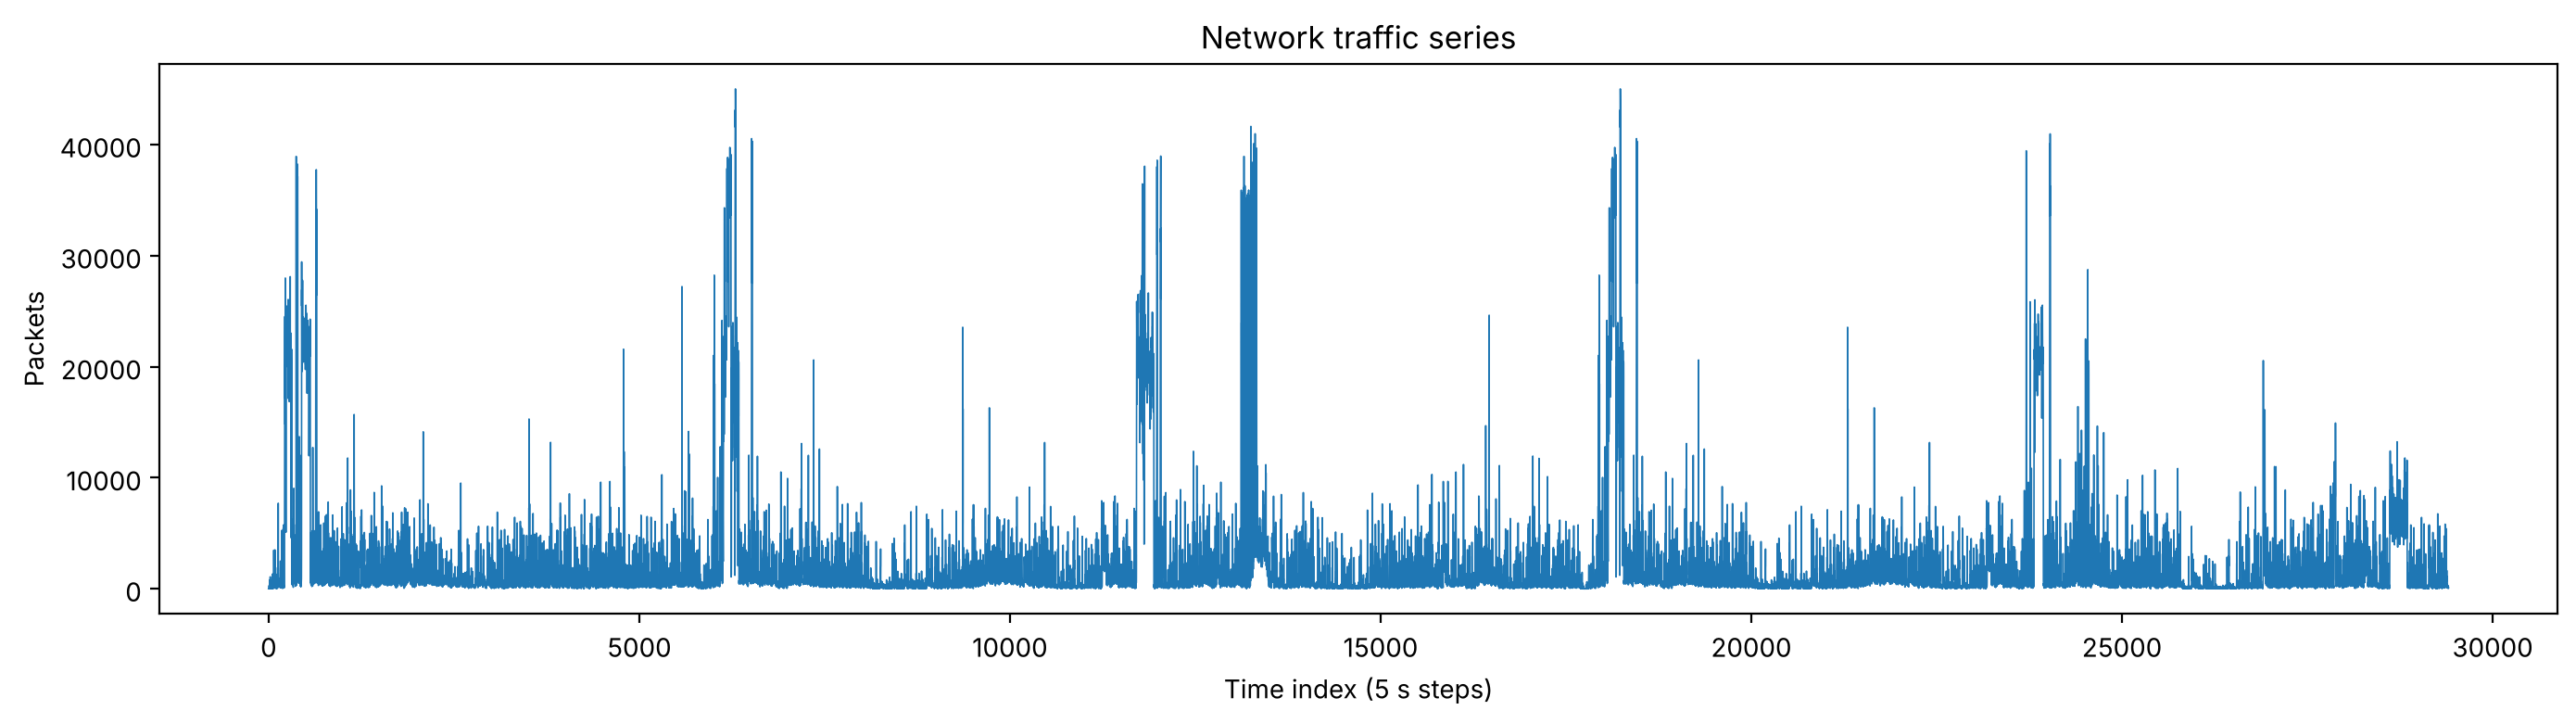

In [3]:
plots.plot_series(series);

## 2. Evaluation protocol
* Every window size forecasts from the same index (`TEST_START = 70`), so all windows are scored on the same targets.
* The evaluation period is split in half: **validation** (to choose window and q) and **test** (to report the error).

In [4]:
split = Split.from_series(len(series), config.TEST_START)
print(f"Full: {split.full} | validation: {split.validation} | test: {split.test}")

Full: (70, 29405) | validation: (70, 14737) | test: (14737, 29405)


## 3. MAE grid (windows 5–70, q ∈ [0.1, 10])

In [5]:
plots.paper_style()
paper = run_grid(series, config.WINDOWS, config.Q_PAPER, *split.full, verbose=False)
wide_table(paper).head(12)

,window,q,PMA,Choquet,CC-min,CT,CF-AVG,CF-nonAVG,CF1F2,dCF,dCC,dXC
0,5,0.1,1320.49,1915.61,1805.27,2007.92,2065.87,1519.05,1516.35,1532.51,1524.27,1537.76
1,5,0.5,1320.49,1402.12,1298.01,1648.10,1746.06,1454.11,1376.83,1531.46,1507.64,1531.21
2,5,1.0,1320.49,1132.93,1123.13,1361.47,1482.58,1440.56,1314.66,1558.47,1498.74,1527.78
3,5,2.0,1320.49,997.75,1035.91,1098.65,1167.64,1459.90,1311.47,1621.64,1499.18,1531.46
4,5,2.5,1320.49,988.07,1026.08,1044.85,1095.25,1475.93,1332.22,1647.60,1505.01,1536.66
5,5,3.0,1320.49,989.18,1022.00,1014.41,1048.92,1490.73,1358.21,1669.14,1512.86,1543.18
6,5,3.5,1320.49,993.94,1019.93,997.19,1022.21,1504.71,1386.06,1686.78,1522.08,1550.57
7,5,4.0,1320.49,999.82,1019.65,987.54,1006.12,1517.04,1413.83,1701.31,1532.10,1558.47
8,5,6.0,1320.49,1020.73,1026.42,981.02,982.39,1554.33,1511.62,1738.98,1573.68,1591.19
9,5,10.0,1320.49,1042.72,1040.72,1002.46,995.32,1592.53,1635.28,1770.53,1641.92,1647.60


Best q (lowest MAE) for each window and operator:

In [6]:
best_q_table(paper)

method,Choquet,CC-min,CT,CF-AVG,CF-nonAVG,CF1F2,dCF,dCC,dXC
window,,,,,,,,,
5,2.5,4.0,6.0,6.0,1.0,2.0,0.5,1.0,1.0
10,2.0,3.0,6.0,6.0,2.0,2.0,0.5,1.0,1.0
15,2.0,3.0,6.0,10.0,2.5,2.0,0.5,1.0,1.0
20,2.0,3.0,6.0,10.0,3.0,2.0,0.5,1.0,1.0
25,2.0,3.0,6.0,10.0,3.5,2.0,0.5,1.0,1.0
30,2.0,3.0,6.0,10.0,4.0,2.5,0.5,1.0,1.0
35,2.0,3.5,6.0,10.0,4.0,2.5,0.1,1.0,1.0
40,2.0,3.5,6.0,10.0,4.0,2.5,0.1,1.0,1.0
45,2.0,3.5,6.0,10.0,6.0,2.5,0.1,1.0,1.0


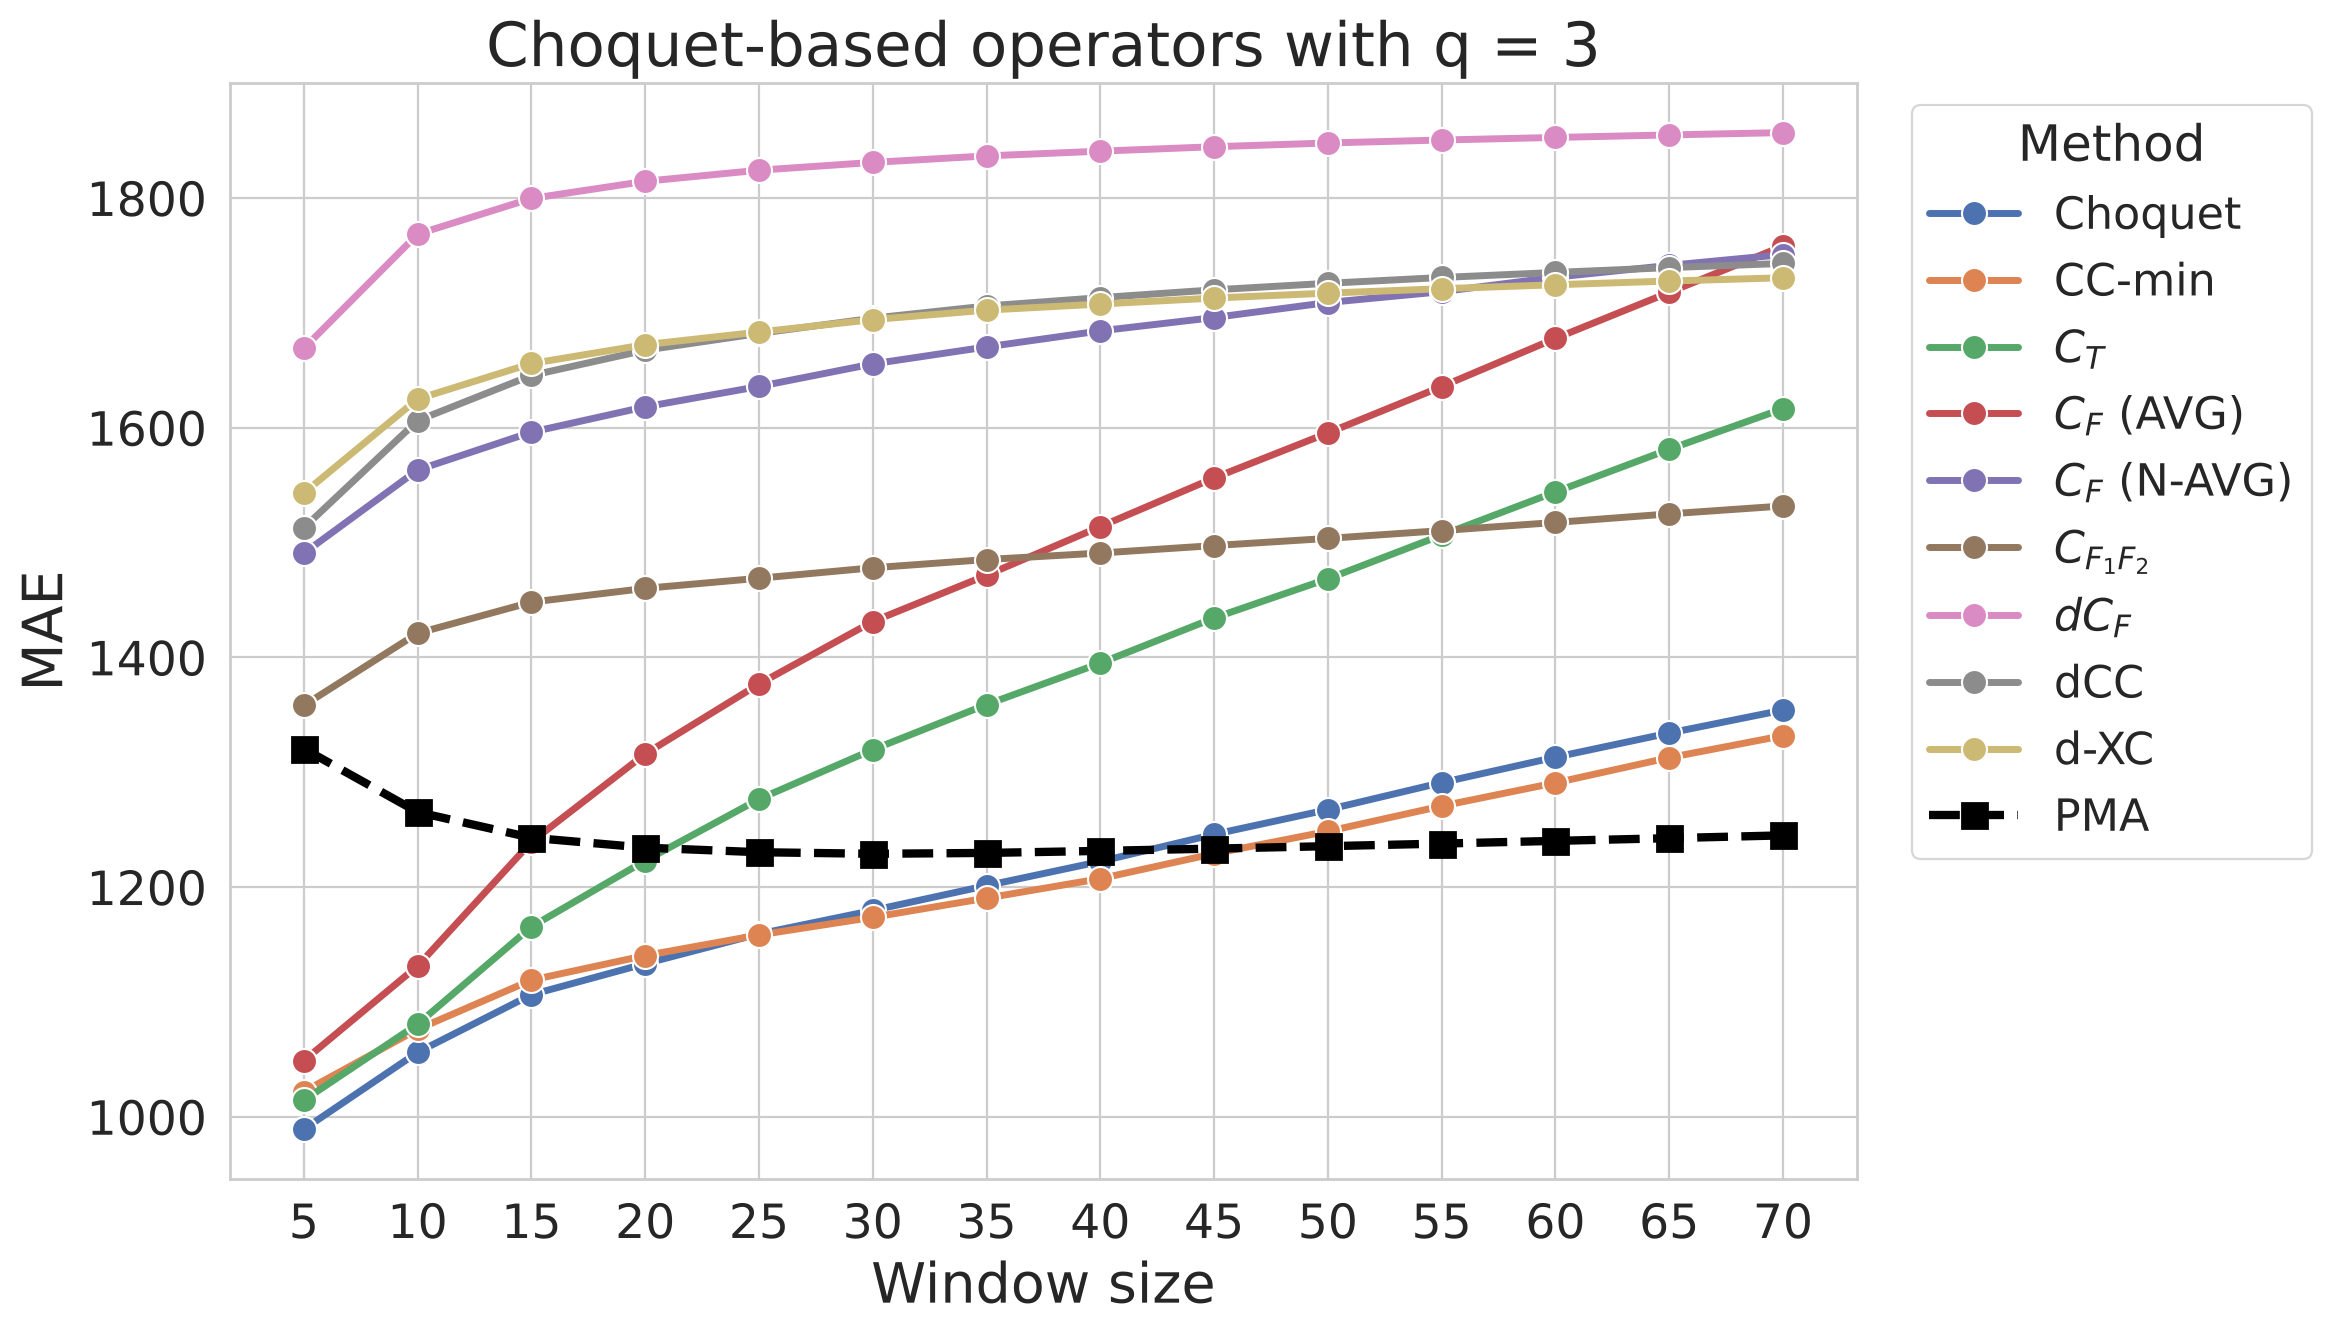

In [7]:
plots.plot_methods(paper, q=3.0);

LaTeX table for one operator (the script writes all of them to `results/tables_paper.tex`):

In [8]:
print(latex_table(paper, "CC-min", config.Q_PAPER))

\begin{table*}[t]
\centering
\caption{Results (MAE) for the $C_C$-integral (min) with the Power Measure exponent $q \in [0.1, 10]$. The lowest MAE for each window is shown in bold.}
\label{tab:ccmin_q}
\resizebox{\textwidth}{!}{%
\begin{tabular}{ccccccccccc}
\toprule
\textbf{Window} & \textbf{$q=0.1$} & \textbf{$q=0.5$} & \textbf{$q=1$} & \textbf{$q=2$} & \textbf{$q=2.5$} & \textbf{$q=3$} & \textbf{$q=3.5$} & \textbf{$q=4$} & \textbf{$q=6$} & \textbf{$q=10$} \\
\midrule
5 & 1805.2669 & 1298.0070 & 1123.1284 & 1035.9066 & 1026.0840 & 1022.0045 & 1019.9340 & \textbf{1019.6478} & 1026.4196 & 1040.7196 \\
10 & 2426.2189 & 1501.9861 & 1211.6860 & 1085.7883 & 1076.7709 & \textbf{1076.2042} & 1077.6059 & 1081.5646 & 1104.7083 & 1136.4394 \\
15 & 2879.2668 & 1668.4681 & 1302.6986 & 1137.4185 & 1122.8106 & \textbf{1119.0491} & 1121.5963 & 1125.8070 & 1153.1819 & 1191.7367 \\
20 & 3241.0213 & 1797.8673 & 1361.7428 & 1162.5887 & 1145.2523 & \textbf{1140.4020} & 1141.0909 & 1144.6210 & 1174.1661 &

Sanity check: d-XC with exponent q is equivalent to dCF with q/4.

In [9]:
dxc_dcf_identity(paper)

,q_dXC,q_dCF,max_abs_diff
0,2.0,0.5,0.0
1,4.0,1.0,0.0


## 4. Selection on validation, error on test

In [10]:
selection = select_on_validation(series, config.WINDOWS, config.Q_GRID, split)
selection

,method,window,q,mae_validation,mae_test
0,Choquet,5,2.50,1126.67,849.49
1,CT,5,3.00,1153.73,875.11
2,CC-min,5,3.00,1164.27,879.75
3,CF-AVG,5,3.00,1191.90,905.94
4,CF1F2,5,1.50,1506.61,1096.61
5,CF-nonAVG,5,0.80,1657.32,1229.81
6,dCC,5,1.25,1740.44,1253.29
7,dXC,5,0.90,1775.17,1281.07
8,dCF,5,0.20,1775.28,1282.00


## 5. CC-min: validation MAE as a function of q

,window,q_best,mae_val_best,mae_val_q1,gain_vs_q1_%,q_band_2%,mae_test_best,mae_test_q1,best_on_grid_edge
0,5,3.7,1160.86,1274.59,8.92,"[2, 8]",878.39,971.67,False
1,10,2.5,1225.60,1352.78,9.40,"[1.75, 4]",927.95,1070.60,False
2,15,2.8,1281.79,1456.39,11.99,"[2, 4]",957.63,1149.02,False
3,20,3.0,1303.51,1520.53,14.27,"[2, 4]",977.30,1202.97,False
4,25,2.8,1324.80,1587.03,16.52,"[2.1, 4]",991.97,1248.66,False
5,30,3.1,1342.85,1637.11,17.97,"[2.2, 4]",1003.16,1288.76,False
6,35,3.2,1364.22,1685.59,19.07,"[2.2, 4]",1013.28,1327.43,False
7,40,3.0,1384.95,1725.94,19.76,"[2.2, 4]",1029.77,1362.29,False


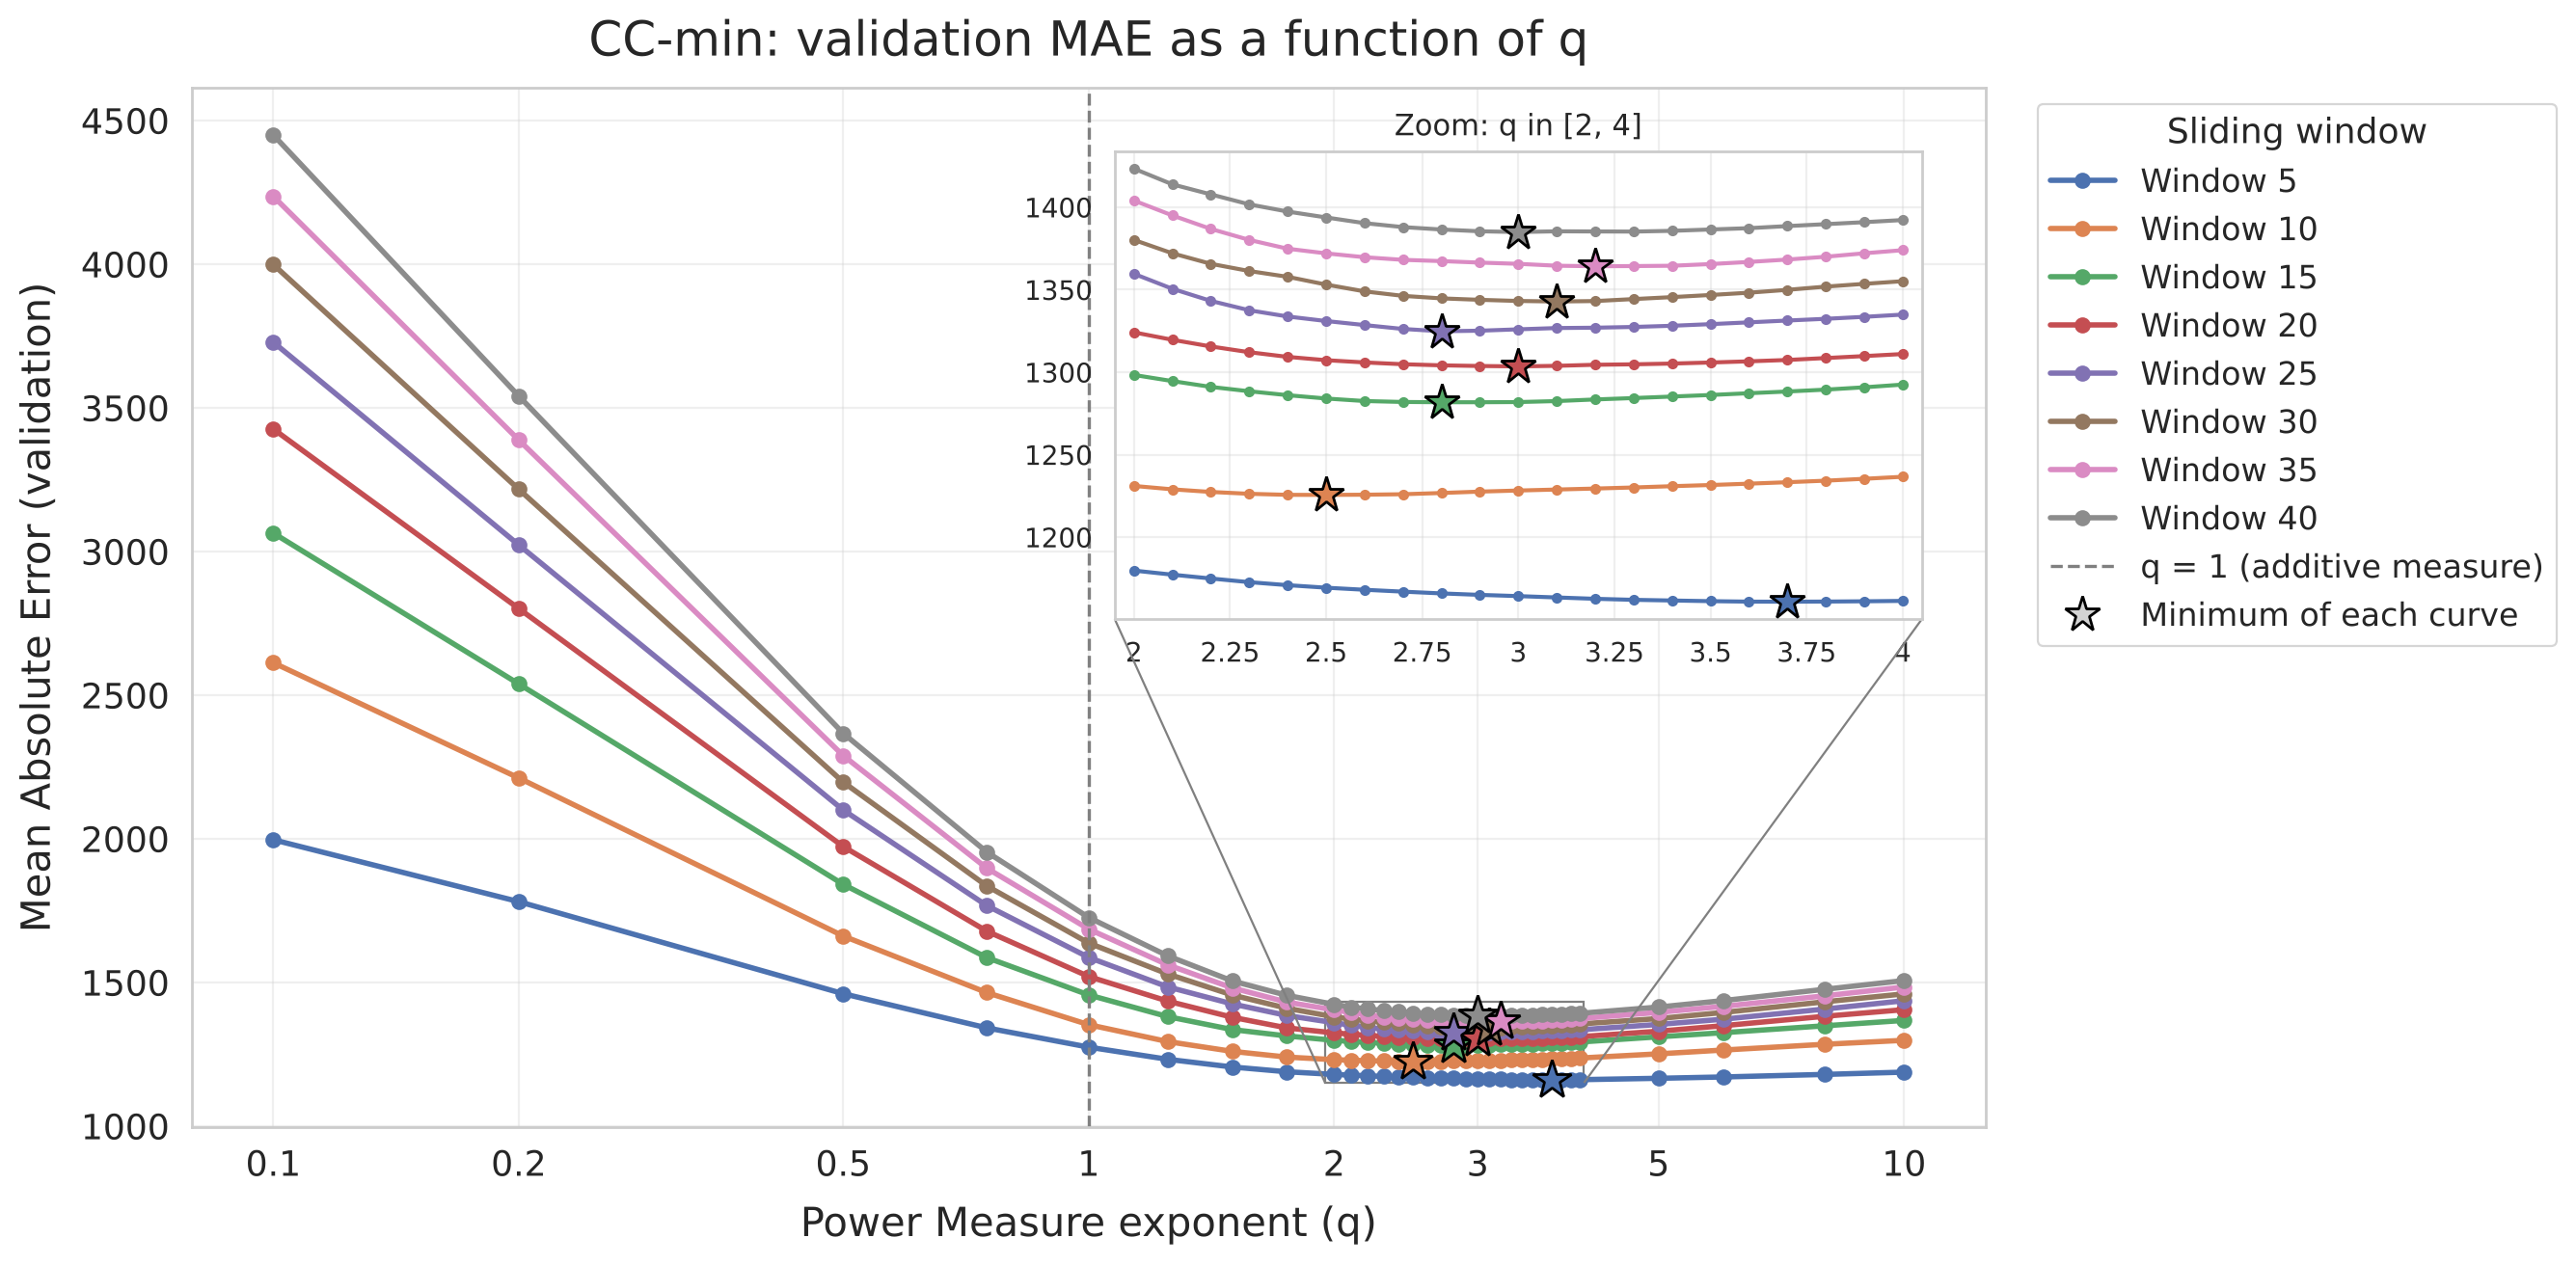

In [11]:
curves = q_curves(series, "CC-min", config.CURVE_WINDOWS, config.Q_CURVE, split)
plots.plot_q_curves(curves, config.Q_CURVE, "CC-min")
ccmin = q_curve_summary(series, "CC-min", curves, config.Q_CURVE, split)
ccmin

## 6. CC-min vs. PMA on the test period

In [12]:
best_q = dict(zip(ccmin["window"], ccmin["q_best"]))
compare_with_pma(series, "CC-min", best_q, split, fixed_q=3.0)

,window,q_best,PMA_test,op_qbest_test,reduction_qbest_vs_PMA_%,op_q3_test,reduction_q3_vs_PMA_%
0,5,3.7,1137.92,878.39,22.81,879.75,22.69
1,10,2.5,1096.14,927.95,15.34,924.15,15.69
2,15,2.8,1079.66,957.63,11.30,956.22,11.43
3,20,3.0,1073.60,977.30,8.97,977.30,8.97
4,25,2.8,1071.04,991.97,7.38,990.74,7.50
5,30,3.1,1070.28,1003.16,6.27,1004.22,6.17
6,35,3.2,1071.40,1013.28,5.42,1015.16,5.25
7,40,3.0,1073.18,1029.77,4.05,1029.77,4.05
